# Logistic Regression and Classification Error Metrics
![LogRegr.png](Assets/LogRegr.png)


# Obiectivele învățării

- Descrieți regresia logistică și modul în care aceasta diferă de regresia liniară
- Identificarea metricilor pentru erorile de clasificare și scenariile în care acestea pot fi utilizate


## Introducere

Vom utiliza baza de date [Human Activity Recognition with Smartphones] (https://archive.ics.uci.edu/ml/datasets/Human+Activity+Recognition+Using+Smartphones), care a fost construită pe baza înregistrărilor participanților la studiu care efectuează activități de viață zilnică (ADL) în timp ce poartă un smartphone cu senzori inerțiali încorporați. Obiectivul este de a clasifica activitățile într-una dintre cele șase activități (mersul pe jos, mersul pe scări, mersul pe scări, șezutul, statul în picioare și întinderea) efectuate.

Pentru fiecare înregistrare din setul de date se furnizează: 

- accelerația triaxială de la accelerometru (accelerația totală) și accelerația corpului estimată. 
- Viteza triaxială unghiulară de la giroscop. 
- Un vector de 561 de caracteristici cu variabile în domeniul timpului și al frecvenței. 
- Eticheta activității sale. 

Mai multe informații despre caracteristici sunt disponibile pe site-ul de mai sus.

In [1]:
from __future__ import print_function
import os
data_path = [ 'data']

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import precision_recall_fscore_support as score
from sklearn.metrics import confusion_matrix, accuracy_score, roc_auc_score
from sklearn.preprocessing import label_binarize



In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
import warnings
warnings.filterwarnings('ignore')

## Întrebarea 1

Importați datele și faceți următoarele:

* Examinați tipurile de date - există multe coloane, astfel încât ar putea fi înțelept să folosiți numărătoarea valorilor
* Determinați dacă valorile în virgulă flotantă trebuie să fie scalate
* Determinați defalcarea fiecărei activități
* Codificați eticheta activității ca un număr întreg

In [3]:
filepath = os.sep.join(data_path + ['Human_Activity_Recognition_Using_Smartphones_Data.csv'])
data = pd.read_csv(filepath)
print(data.shape)
data.dtypes.value_counts()

(10299, 562)


float64    561
str          1
Name: count, dtype: int64

Coloanele de date sunt toate flotante, cu excepția etichetei de activitate.

In [4]:
feature_cols = data.columns[:-1]
print('min:', data[feature_cols].min().min())
print('max:', data[feature_cols].max().max())

min: -1.0
max: 1.0


Toate datele sunt scalate de la -1 (minim) la 1.0 (maxim).

In [5]:
data['Activity'].value_counts()

Activity
LAYING                1944
STANDING              1906
SITTING               1777
WALKING               1722
WALKING_UPSTAIRS      1544
WALKING_DOWNSTAIRS    1406
Name: count, dtype: int64

Examinați defalcarea activităților - acestea sunt relativ echilibrate.

Clasificatoarele Scikit learn nu vor accepta o matrice dispersată pentru coloana de predicție. Astfel, fie trebuie utilizat `LabelEncoder` pentru a converti etichetele de activitate în numere întregi, fie, dacă se utilizează `DictVectorizer`, matricea rezultată trebuie convertită într-o matrice non-sparse.  
Utilizați `LabelEncoder` pentru a fit_transforma coloana „Activity” și analizați 5 valori aleatorii.

In [6]:
le = LabelEncoder()
data['Activity'] = le.fit_transform(data['Activity'])

print(le.classes_)
data['Activity'].sample(5)

['LAYING' 'SITTING' 'STANDING' 'WALKING' 'WALKING_DOWNSTAIRS'
 'WALKING_UPSTAIRS']


1483    2
966     4
9545    5
7176    2
13      2
Name: Activity, dtype: int64

Toate coloanele sunt float, doar `Activity` e text. Valorile sunt deja între -1 și 1, deci nu mai trebuie scalate. Clasele sunt destul de echilibrate (între ~1400 și ~1950 de rânduri). Am codificat `Activity` în numere de la 0 la 5.

## Întrebarea 2

* Calculați corelațiile dintre variabilele dependente.
* Creați o histogramă a valorilor corelației
* Identificați cele care sunt cele mai corelate (fie pozitiv, fie negativ).

In [7]:
corr_values = data[feature_cols].corr()

# pastram doar triunghiul de sus, ca sa nu avem perechi dublate
mask = np.triu(np.ones(corr_values.shape), k=1).astype(bool)
corr_values = corr_values.where(mask).stack().reset_index()
corr_values.columns = ['feature1', 'feature2', 'correlation']
corr_values['abs_correlation'] = corr_values['correlation'].abs()

O histogramă a corelațiilor valorii absolute.

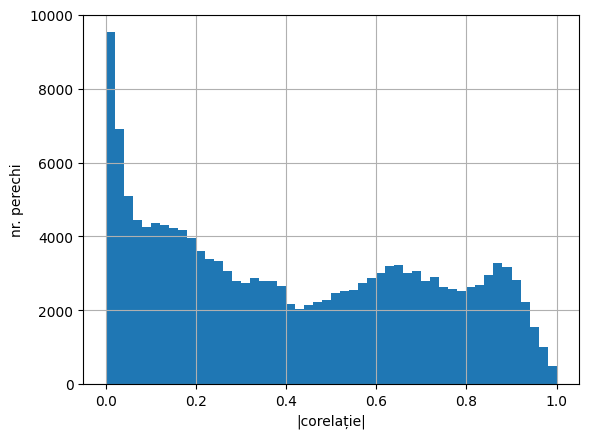

In [8]:
corr_values['abs_correlation'].hist(bins=50)
plt.xlabel('|corelație|')
plt.ylabel('nr. perechi')
plt.show()

In [9]:
corr_values.sort_values('abs_correlation', ascending=False).head(10)

,feature1,feature2,correlation,abs_correlation
112413,tBodyAccMag-mean(),tGravityAccMag-mean(),1.0,1.0
112418,tBodyAccMag-mean(),tGravityAccMag-sma(),1.0,1.0
112405,tBodyAccMag-mean(),tBodyAccMag-sma(),1.0,1.0
112975,tBodyAccMag-std(),tGravityAccMag-std(),1.0,1.0
113537,tBodyAccMag-mad(),tGravityAccMag-mad(),1.0,1.0
127017,tBodyAccJerkMag-mean(),tBodyAccJerkMag-sma(),1.0,1.0
296741,fBodyBodyGyroMag-mean(),fBodyBodyGyroMag-sma(),1.0,1.0
304047,fBodyBodyGyroJerkMag-mean(),fBodyBodyGyroJerkMag-sma(),1.0,1.0
141629,tBodyGyroJerkMag-mean(),tBodyGyroJerkMag-sma(),1.0,1.0
115785,tBodyAccMag-energy(),tGravityAccMag-energy(),1.0,1.0


Multe caracteristici sunt foarte corelate între ele, sunt chiar perechi cu corelația 1 (de ex. `tBodyAccMag-mean()` și `tGravityAccMag-mean()`). Asta pentru că multe coloane sunt calculate din aceleași semnale. Pe histogramă se vede un grup mare de perechi cu corelație peste 0.8.

## Întrebare 3

* Împărțiți datele în seturi de date de instruire și de testare. Acest lucru se poate face folosind orice metodă, dar luați în considerare utilizarea `StratifiedShuffleSplit` din Scikit-learn pentru a menține același raport al claselor de predictori.
* Indiferent de metodele utilizate pentru împărțirea datelor, comparați raportul claselor în ambele împărțiri, de formare și de testare.


In [10]:
strat_shuf_split = StratifiedShuffleSplit(n_splits=1, test_size=0.3, random_state=42)
train_idx, test_idx = next(strat_shuf_split.split(data[feature_cols], data['Activity']))

X_train = data.loc[train_idx, feature_cols]
y_train = data.loc[train_idx, 'Activity']
X_test = data.loc[test_idx, feature_cols]
y_test = data.loc[test_idx, 'Activity']

In [11]:
pd.DataFrame({'train': y_train.value_counts(normalize=True),
              'test': y_test.value_counts(normalize=True)})

,train,test
Activity,,
0,0.188792,0.188673
2,0.185046,0.185113
1,0.172562,0.172492
3,0.167152,0.167314
5,0.149951,0.149838
4,0.136496,0.136570


Proporțiile claselor sunt practic aceleași în train și test, deci StratifiedShuffleSplit a păstrat raportul claselor.

## Întrebare 4

* Ajustați un model de regresie logistică fără regularizare folosind toate caracteristicile. Asigurați-vă că citiți documentația despre ajustarea unui model multiclasă, astfel încât să înțelegeți coeficientul de ieșire. Stocați modelul.
* Folosind validarea încrucișată pentru a determina hiperparametrii, ajustați modelele folosind regularizarea L1 și L2. De asemenea, stocați fiecare dintre aceste modele. Rețineți limitările privind modelele, soluțiile și regularizările multiclasă. Modelele regularizate, în special modelul L1, vor dura probabil ceva timp pentru a fi ajustate.

In [12]:
lr = LogisticRegression(penalty=None, max_iter=1000).fit(X_train, y_train)

In [13]:
# L1 dureaza cel mai mult, de asta putine valori pentru C
lr_l1 = LogisticRegressionCV(Cs=[0.1, 1, 10], cv=3, penalty='l1', solver='saga', n_jobs=-1).fit(X_train, y_train)

In [14]:
lr_l2 = LogisticRegressionCV(Cs=10, cv=4, penalty='l2', n_jobs=-1).fit(X_train, y_train)

print('C optim L1:', lr_l1.C_[0])
print('C optim L2:', lr_l2.C_[0])

C optim L1: 10.0
C optim L2: 2.782559402207126


Modelele sunt multiclasă, deci `coef_` are 6 rânduri, câte unul pentru fiecare activitate. Pentru L1 la multiclasă am folosit solverul `saga`, iar acest model durează cel mai mult.

## Întrebarea 5

Comparați mărimile coeficienților pentru fiecare dintre modele. Dacă s-a utilizat ajustarea unu-vs-rest, fiecare set de coeficienți poate fi reprezentat separat. 

In [15]:
models = {'lr': lr, 'l1': lr_l1, 'l2': lr_l2}

for name, mod in models.items():
    print(name, 'media |coef|:', np.abs(mod.coef_).mean().round(3), '  coef = 0:', (mod.coef_ == 0).sum())

lr media |coef|: 10.397   coef = 0: 0
l1 media |coef|: 0.152   coef = 0: 410
l2 media |coef|: 0.228   coef = 0: 0


Pregătiți șase diagrame separate pentru fiecare dintre coeficienții multi-clasă.

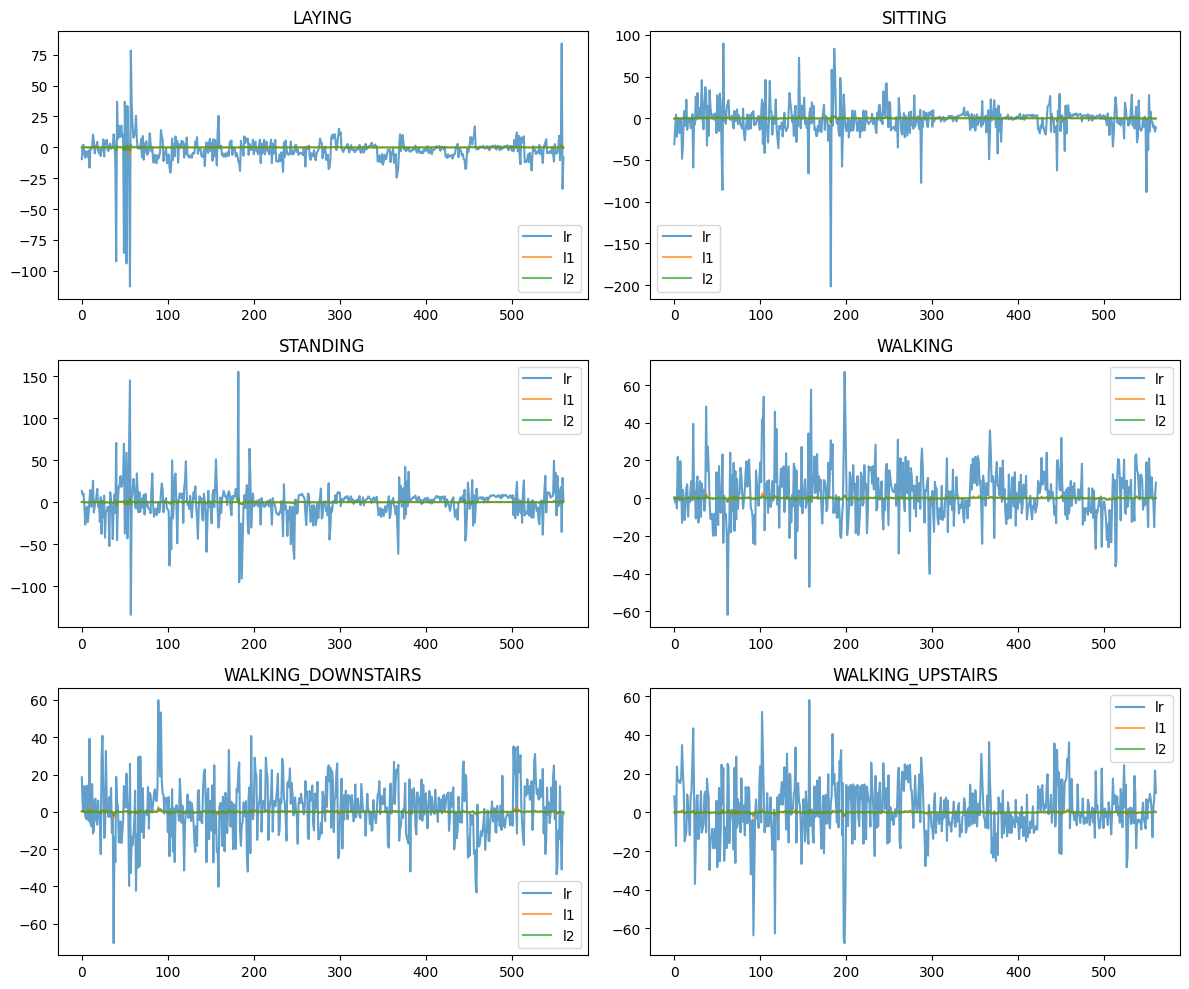

In [16]:
fig, axes = plt.subplots(3, 2, figsize=(12, 10))

for i, ax in enumerate(axes.flatten()):
    for name, mod in models.items():
        ax.plot(mod.coef_[i], label=name, alpha=0.7)
    ax.set_title(le.classes_[i])
    ax.legend()

plt.tight_layout()
plt.show()

Modelul fără regularizare are coeficienți mult mai mari (media ~10, unii ajung la ±200). La L1 și L2 coeficienții sunt mici (sub 1 în medie), iar L1 pune 410 coeficienți pe 0. Pe grafice liniile pentru L1 și L2 aproape nu se văd, pentru că sunt foarte mici față de `lr`.

## Întrebare 6

* Preziceți și stocați clasa pentru fiecare model.
* De asemenea, stocați probabilitatea pentru clasa prezisă pentru fiecare model. 

In [17]:
y_pred = pd.DataFrame()
y_prob = pd.DataFrame()

for name, mod in models.items():
    y_pred[name] = mod.predict(X_test)
    y_prob[name] = mod.predict_proba(X_test).max(axis=1)

y_pred.head()

,lr,l1,l2
0,3,3,3
1,5,5,5
2,3,3,3
3,1,1,1
4,0,0,0


In [18]:
y_prob.head()

,lr,l1,l2
0,1.0,0.999998,0.999997
1,1.0,0.999750,0.999708
2,1.0,0.999382,0.998930
3,1.0,0.997907,0.997764
4,1.0,0.999002,0.999376


## Întrebarea 7

Pentru fiecare model, calculați următoarele măsurători de eroare: 

* acuratețe
* precizie
* recall
* fscore
* matricea de confuzie

Decideți cum să combinați metricile multi-clasă într-o singură valoare pentru fiecare model.

In [19]:
metrics = pd.DataFrame()
cm = {}

for name in models:
    precision, recall, fscore, _ = score(y_test, y_pred[name], average='weighted')
    metrics[name] = [accuracy_score(y_test, y_pred[name]), precision, recall, fscore]
    cm[name] = confusion_matrix(y_test, y_pred[name])

metrics.index = ['accuracy', 'precision', 'recall', 'fscore']
metrics

,lr,l1,l2
accuracy,0.982524,0.983495,0.983819
precision,0.982513,0.983488,0.983810
recall,0.982524,0.983495,0.983819
fscore,0.982513,0.983487,0.983811


In [20]:
cm['lr']

array([[583,   0,   0,   0,   0,   0],
       [  1, 510,  21,   0,   0,   1],
       [  0,  24, 548,   0,   0,   0],
       [  0,   0,   0, 517,   0,   0],
       [  0,   0,   0,   0, 419,   3],
       [  0,   0,   0,   4,   0, 459]])

Am combinat metricile pentru cele 6 clase cu `average='weighted'` (medie ponderată după numărul de exemple din fiecare clasă), pentru că clasele sunt aproape echilibrate. Toate trei modelele au ~98% la toate metricile, diferențele sunt foarte mici. L2 iese puțin mai bine.

## Întrebarea 8

Afișați sau reprezentați grafic matricea de confuzie pentru fiecare model.

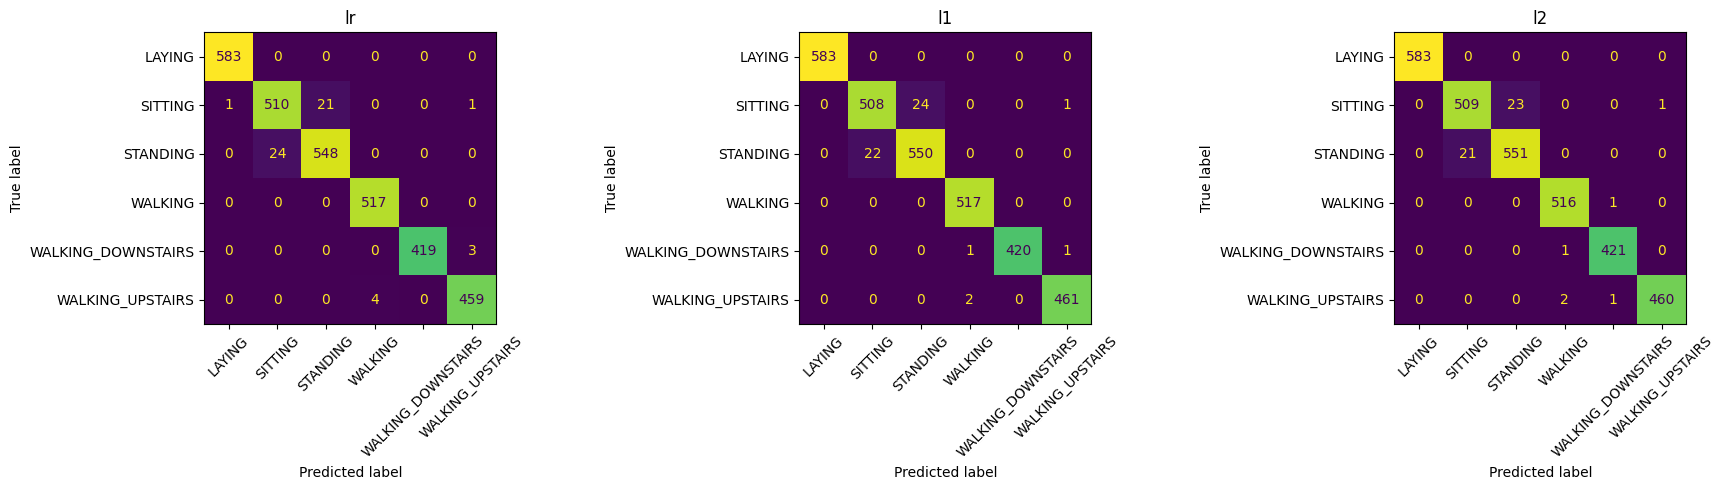

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, name in zip(axes, models):
    ConfusionMatrixDisplay(cm[name], display_labels=le.classes_).plot(ax=ax, colorbar=False, xticks_rotation=45)
    ax.set_title(name)

plt.tight_layout()
plt.show()

Toate modelele greșesc aproape doar între SITTING și STANDING. E logic, pentru că în ambele cazuri telefonul aproape nu se mișcă. Celelalte activități sunt clasificate aproape perfect.